# Classification du type d'anomalie avec ResNet-50 (DSO 2)

Chaque cellule de code est précédée d'une explication de ce qu'elle fait et suivie d'une explication de son résultat.

**Installation.** Installe PyTorch et torchvision (version GPU CUDA 12.6), les bibliothèques de deep learning utilisées dans tout le notebook.

In [3]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126

Looking in indexes: https://download.pytorch.org/whl/cu126
   ---------------------------------------- 0.0/2.6 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 GB 1.4 MB/s eta 0:30:54
   ---------------------------------------- 0.0/2.6 GB 1.2 MB/s eta 0:35:25
   ---------------------------------------- 0.0/2.6 GB 1.2 MB/s eta 0:35:25
   ---------------------------------------- 0.0/2.6 GB 980.8 kB/s eta 0:44:34
   ---------------------------------------- 0.0/2.6 GB 980.8 kB/s eta 0:44:34
   ---------------------------------------- 0.0/2.6 GB 1.1 MB/s eta 0:40:37
   ---------------------------------------- 0.0/2.6 GB 1.1 MB/s eta 0:40:37
   ---------------------------------------- 0.0/2.6 GB 1.1 MB/s eta 0:40:57
   ---------------------------------------- 0.0/2.6 G

**Résultat.** Les paquets sont téléchargés et installés ; les dépendances déjà présentes sont simplement ignorées.

**Imports et configuration.** Importe les bibliothèques, indique où sont les données (`DataPreparation`), fixe `manual_seed(42)` pour avoir les mêmes résultats à chaque exécution, et choisit le GPU s'il existe, sinon le CPU.

In [3]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

DOSSIER = r"C:\Users\troud\Desktop\RoadAnomaly"
if not os.path.isdir(os.path.join(DOSSIER, "frames")):
    DOSSIER = os.path.join(DOSSIER, "RoadAnomaly")
PREP = os.path.join(DOSSIER, "frames", "DataPreparation")

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Appareil :", device)

Appareil : cpu


**Résultat.** `Appareil : cpu` : aucun GPU n'est utilisé, tout tourne sur le processeur. Ça marche, mais l'entraînement est plus lent.

**Chargement des étiquettes.** Lit `etiquettes.csv` (classe, photo d'origine et ensemble de chaque image), transforme la classe en nombre (0, 1, 2), puis calcule le pourcentage de l'image occupé par l'anomalie grâce au masque.

In [6]:
CLASSES = ["animals", "obstacles", "cones"]
etiquettes = pd.read_csv(f"{PREP}/etiquettes.csv")
etiquettes["label"] = etiquettes["classe"].map({c: i for i, c in enumerate(CLASSES)})

etiquettes["anomalie_%"] = [
    (np.array(Image.open(f"{PREP}/{e}/masques/{n}.png")) > 0).mean() * 100
    for n, e in zip(etiquettes.nom, etiquettes.ensemble)
]
print(etiquettes.groupby("classe")["anomalie_%"].mean().round(1))
print("Photos d'origine par ensemble :")
print(etiquettes.groupby("ensemble")["source"].nunique())

classe
animals      12.6
cones         2.8
obstacles     9.5
Name: anomalie_%, dtype: float64
Photos d'origine par ensemble :
ensemble
test      9
train    37
val       8
Name: source, dtype: int64


**Résultat.**
- L'anomalie occupe peu de place : **12,6 %** pour animals, **9,5 %** pour obstacles, **2,8 %** pour cones. Le reste de l'image est du décor, d'où l'intérêt de recadrer sur l'objet.
- Photos d'origine : **37 en train, 8 en validation, 9 en test**. La séparation se fait par photo d'origine, donc aucune copie d'une même photo n'est à la fois en train et en test (pas de triche).

**Recadrage autour de l'anomalie.** La fonction `recadrer` isole les objets du masque, garde le plus grand et découpe l'image autour avec 20 % de marge. Le code affiche ensuite, pour chaque classe, l'image entière (haut) et l'image recadrée (bas).

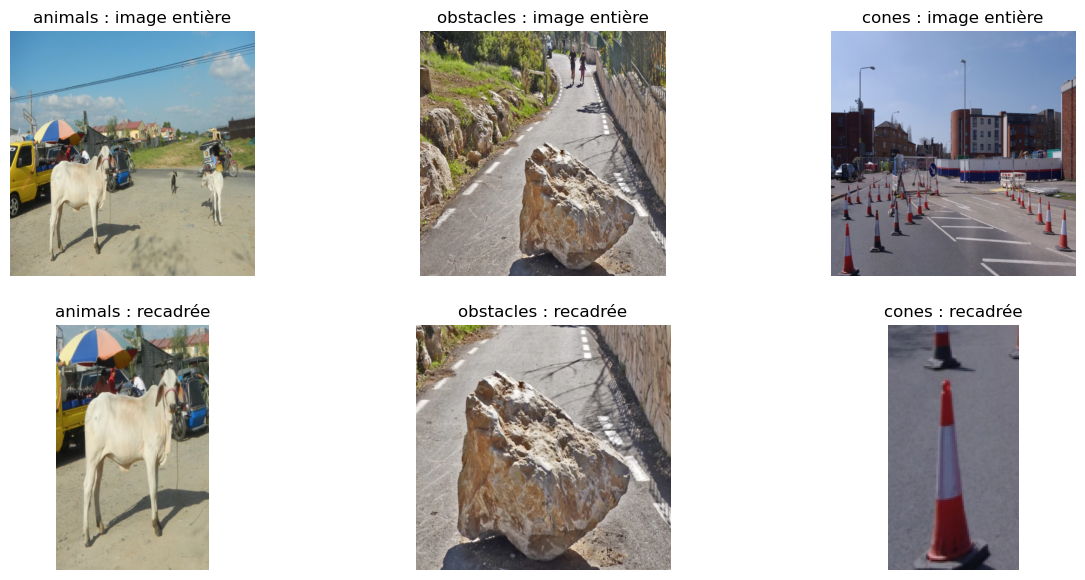

In [8]:
def recadrer(nom, ensemble, marge=0.2):
    img = Image.open(f"{PREP}/{ensemble}/images/{nom}.png").convert("RGB")
    masque = np.array(Image.open(f"{PREP}/{ensemble}/masques/{nom}.png")) > 0
    objets, n = ndimage.label(masque)
    if n == 0:
        return img
    tailles = ndimage.sum(masque, objets, range(1, n + 1))
    ys, xs = np.where(objets == np.argmax(tailles) + 1)
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    dx, dy = int((x1 - x0) * marge) + 10, int((y1 - y0) * marge) + 10
    return img.crop((max(x0 - dx, 0), max(y0 - dy, 0), min(x1 + dx, img.width), min(y1 + dy, img.height)))

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(CLASSES):
    ligne = etiquettes[(etiquettes.classe == c) & (etiquettes.ensemble == "train")].iloc[0]
    ax[0, i].imshow(Image.open(f"{PREP}/train/images/{ligne.nom}.png")); ax[0, i].set_title(f"{c} : image entière")
    ax[1, i].imshow(recadrer(ligne.nom, "train")); ax[1, i].set_title(f"{c} : recadrée")
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.show()

**Résultat.** Sur la ligne du bas, l'objet remplit presque toute l'image, alors qu'il est petit sur la ligne du haut. Le modèle se concentrera sur l'objet et non sur la route ou le décor.

**Chargement de ResNet-50.** Charge ResNet-50 **déjà entraîné sur ImageNet** (transfer learning) : il sait déjà reconnaître formes et textures. Affiche sa dernière couche `fc`.

In [16]:
model = models.resnet50(weights="IMAGENET1K_V1")
print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to C:\Users\troud/.cache\torch\hub\checkpoints\resnet50-0676ba61.pth


100%|█████████████████████████████████████████████████████████████████████████████| 97.8M/97.8M [00:34<00:00, 2.98MB/s]

Linear(in_features=2048, out_features=1000, bias=True)


**Résultat.** Le poids du modèle (97,8 Mo) est téléchargé. `Linear(2048 → 1000)` : la tête d'origine prédit les 1000 classes d'ImageNet, alors que nous n'en avons que 3. Il faut donc la remplacer.

**Remplacement de la tête.** Remplace `fc` par notre tête : Linear 2048 → 256, ReLU, Dropout 0,5 (éteint 50 % des neurones au hasard pendant l'entraînement contre le surapprentissage), puis Linear 256 → 3 (une sortie par classe). Affiche tout le modèle.

In [19]:
model.fc = nn.Sequential(
    nn.Linear(2048, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 3),
)
model = model.to(device)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

**Résultat.** La structure complète de ResNet-50 s'affiche : `conv1` → `bn1` → `relu` → `maxpool` → `layer1` à `layer4` (blocs « bottleneck ») → `avgpool` → `fc`. À la fin, on retrouve notre nouvelle tête avec 3 sorties.

**Vérification de l'architecture.** Compte les types de couches et le nombre de paramètres.

In [22]:
couches = pd.Series([type(m).__name__ for m in model.modules()]).value_counts()
print(couches[["Conv2d", "ReLU", "MaxPool2d", "AdaptiveAvgPool2d", "Linear"]])
print("Paramètres :", round(sum(p.numel() for p in model.parameters()) / 1e6, 1), "millions")

Conv2d               53
ReLU                 18
MaxPool2d             1
AdaptiveAvgPool2d     1
Linear                2
Name: count, dtype: int64
Paramètres : 24.0 millions


**Résultat.**
- **53** convolutions (`Conv2d`), **18** `ReLU`, **1** `MaxPool2d`, **1** `AdaptiveAvgPool2d` (pooling), **2** `Linear` (notre tête).
- **24,0 millions** de paramètres.

On retrouve bien l'enchaînement demandé : Convolution → Activation → Pooling → Fully Connected → Sortie.

**Perte et fonctions d'entraînement.** `CrossEntropyLoss` mesure l'erreur de classification ; le *label smoothing* (0,1) demande au modèle d'être sûr à 90 % au lieu de 100 %. `entrainer_une_epoque` fait apprendre le modèle sur tout le train ; `evaluer` mesure perte, accuracy et F1 sans rien modifier.

In [25]:
critere = nn.CrossEntropyLoss(label_smoothing=0.1) #applique le softmax en interne

def entrainer_une_epoque(model, dl, optimiseur):
    model.train()
    perte_totale, bons = 0, 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        optimiseur.zero_grad()
        sortie = model(x)
        perte = critere(sortie, y)
        perte.backward()
        optimiseur.step()
        perte_totale += perte.item() * len(y)
        bons += (sortie.argmax(1) == y).sum().item()
    return perte_totale / len(dl.dataset), bons / len(dl.dataset)

@torch.no_grad()
def evaluer(model, dl):
    model.eval()
    perte_totale, vrais, preds = 0, [], []
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        sortie = model(x)
        perte_totale += critere(sortie, y).item() * len(y)
        preds += sortie.argmax(1).tolist()
        vrais += y.tolist()
    return perte_totale / len(dl.dataset), accuracy_score(vrais, preds), f1_score(vrais, preds, average="macro"), vrais, preds

**Résultat.** Aucun affichage : ce sont seulement des définitions utilisées dans les cellules suivantes.

**Entraînement 1 : seulement la tête.** Gèle tout le modèle sauf `fc` : seule la nouvelle tête apprend (5 époques, lr = 0,001, optimiseur AdamW). On garde ainsi ce que ResNet-50 sait déjà.

In [28]:
for p in model.parameters():
    p.requires_grad = False
for p in model.fc.parameters():
    p.requires_grad = True
optimiseur = torch.optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=0.01)

historique = []
for epoque in range(5):
    perte_train, acc_train = entrainer_une_epoque(model, train_dl, optimiseur)
    perte_val, acc_val, f1_val, _, _ = evaluer(model, val_dl)
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "acc_train": acc_train, "acc_val": acc_val, "f1_val": f1_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   accuracy {acc_train:.0%} / {acc_val:.0%}   F1 val {f1_val:.2f}")

Époque 1 : perte 0.588 / 0.482   accuracy 83% / 91%   F1 val 0.91
Époque 2 : perte 0.362 / 0.338   accuracy 99% / 100%   F1 val 1.00
Époque 3 : perte 0.334 / 0.349   accuracy 100% / 100%   F1 val 1.00
Époque 4 : perte 0.326 / 0.338   accuracy 100% / 100%   F1 val 1.00
Époque 5 : perte 0.334 / 0.361   accuracy 100% / 100%   F1 val 1.00


**Résultat.**
- Époque 1 : 83 % en train, 91 % en validation.
- Dès l'époque 2 : ~99-100 % en train et **100 %** en validation, F1 = 1,00.
- La perte reste autour de 0,33 et ne tombe pas à 0 : c'est normal à cause du label smoothing.

La tâche est donc apprise très vite, car ResNet-50 extrait déjà de bonnes caractéristiques.

**Entraînement 2 : dernier bloc + early stopping.** Dégèle `layer4` (le dernier groupe de blocs, qui reconnaît les formes complexes) avec un lr 10 fois plus petit (0,0001) pour affiner sans tout casser. Le meilleur modèle est sauvegardé ; l'*early stopping* arrête l'entraînement si le F1 de validation ne progresse plus pendant 5 époques.

In [31]:
for p in model.layer4.parameters():
    p.requires_grad = True
optimiseur = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=0.01)
entrainables = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Paramètres entraînés :", round(entrainables / 1e6, 1), "millions")

meilleur_f1, attente, PATIENCE = 0, 0, 5
for epoque in range(30):
    perte_train, acc_train = entrainer_une_epoque(model, train_dl, optimiseur)
    perte_val, acc_val, f1_val, _, _ = evaluer(model, val_dl)
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "acc_train": acc_train, "acc_val": acc_val, "f1_val": f1_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   accuracy {acc_train:.0%} / {acc_val:.0%}   F1 val {f1_val:.2f}")
    if f1_val > meilleur_f1:
        meilleur_f1, attente = f1_val, 0
        torch.save(model.state_dict(), "resnet50_meilleur.pt")
    else:
        attente += 1
        if attente == PATIENCE:
            print("Early stopping : le F1 de validation ne progresse plus")
            break
print("Meilleur F1 de validation :", round(meilleur_f1, 3))

Paramètres entraînés : 15.5 millions
Époque 1 : perte 0.328 / 0.342   accuracy 100% / 100%   F1 val 1.00
Époque 2 : perte 0.320 / 0.362   accuracy 100% / 100%   F1 val 1.00
Époque 3 : perte 0.316 / 0.372   accuracy 100% / 100%   F1 val 1.00
Époque 4 : perte 0.311 / 0.347   accuracy 100% / 100%   F1 val 1.00
Époque 5 : perte 0.315 / 0.336   accuracy 100% / 100%   F1 val 1.00
Époque 6 : perte 0.314 / 0.336   accuracy 100% / 100%   F1 val 1.00
Early stopping : le F1 de validation ne progresse plus
Meilleur F1 de validation : 1.0


**Résultat.**
- **15,5 millions** de paramètres entraînés (contre seulement la tête avant).
- Le F1 de validation vaut déjà 1,00 et ne peut plus monter : après 5 époques sans progrès, l'entraînement s'arrête à l'époque 6.
- Meilleur F1 de validation : **1,0**.

**Courbes d'apprentissage.** Trace la perte et l'accuracy en train et en validation ; la ligne grise sépare les deux entraînements.

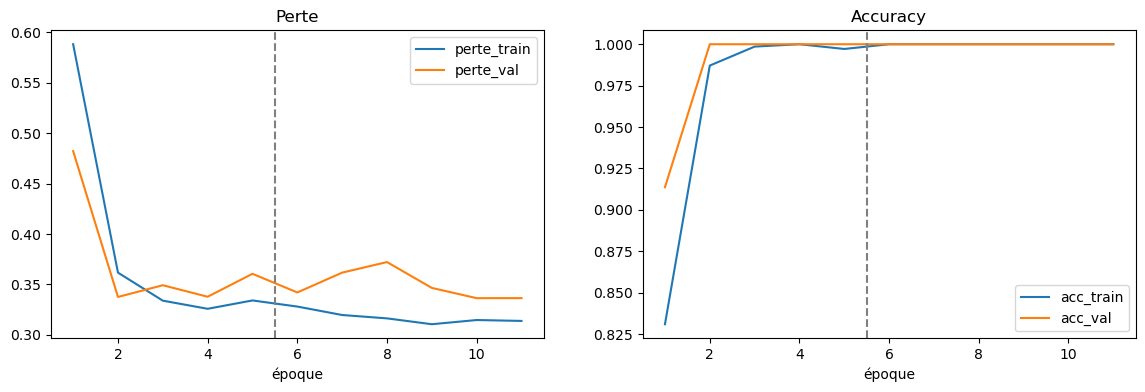

In [34]:
h = pd.DataFrame(historique)
h.index = h.index + 1
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
h[["perte_train", "perte_val"]].plot(ax=ax[0], title="Perte")
h[["acc_train", "acc_val"]].plot(ax=ax[1], title="Accuracy")
for a in ax:
    a.axvline(5.5, color="gray", linestyle="--")
    a.set_xlabel("époque")
plt.show()

**Résultat.**
- La perte chute vite puis reste stable (~0,31 à 0,37) ; l'accuracy atteint ~100 % dès l'époque 2.
- Les courbes train et validation restent proches : **pas de surapprentissage marqué**.
- Attention : la validation ne contient que 8 photos, donc 100 % est peu informatif. Le test est plus fiable.

**Évaluation finale.** Recharge le meilleur modèle sauvegardé, le mesure sur la validation puis sur le test. Le *score par photo* fait voter les ~20 copies de chaque photo d'origine. Affiche le rapport de classification et la matrice de confusion.

Validation : accuracy = 100.0%   F1 macro = 1.00   photos bien classées = 100% sur 8
Test : accuracy = 96.9%   F1 macro = 0.97   photos bien classées = 100% sur 9
              precision    recall  f1-score   support

     animals       1.00      0.91      0.95        54
   obstacles       0.93      1.00      0.96        67
       cones       1.00      1.00      1.00        42

    accuracy                           0.97       163
   macro avg       0.98      0.97      0.97       163
weighted avg       0.97      0.97      0.97       163



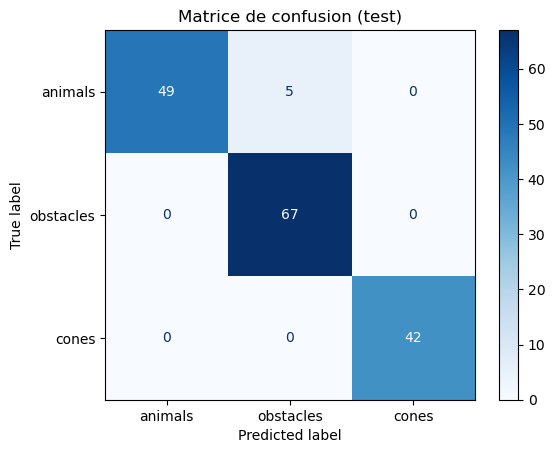

In [37]:
model.load_state_dict(torch.load("resnet50_meilleur.pt", map_location=device))

def score_par_photo(ds, vrais, preds):
    d = ds.df.assign(vrai=vrais, pred=preds)
    vote = d.groupby("source").agg(vrai=("vrai", "first"), pred=("pred", lambda p: p.mode()[0]))
    return (vote.vrai == vote.pred).mean(), len(vote)

for nom, ds, dl in [("Validation", val_ds, val_dl), ("Test", test_ds, test_dl)]:
    _, acc, f1, vrais, preds = evaluer(model, dl)
    acc_photo, n_photos = score_par_photo(ds, vrais, preds)
    print(f"{nom} : accuracy = {acc:.1%}   F1 macro = {f1:.2f}   photos bien classées = {acc_photo:.0%} sur {n_photos}")

print(classification_report(vrais, preds, target_names=CLASSES))
ConfusionMatrixDisplay(confusion_matrix(vrais, preds), display_labels=CLASSES).plot(cmap="Blues")
plt.title("Matrice de confusion (test)")
plt.show()

**Résultat.**
- Validation : accuracy **100 %**, F1 macro 1,00.
- **Test : accuracy 96,9 %, F1 macro 0,97**, et **9 photos sur 9** bien classées par vote.
- Par classe : `cones` parfait (1,00 partout) ; `obstacles` rappel 1,00 mais précision 0,93 ; `animals` précision 1,00 mais rappel 0,91.
- Matrice de confusion : sur 163 images de test, **5 animaux sont pris pour des obstacles**, aucune autre erreur.

Le modèle confond seulement parfois un animal avec un obstacle, ce qui est logique, car ces deux classes peuvent se ressembler (forme sombre sur la route).